# 1A-6. 고장신고율 EDA

**이 노트북이 답하려는 질문**: 이용량(노출)으로 나눈 뒤에도 신고율을 움직이는 것은 무엇인가? 요일, 쉬는 날, 비, 기온, 계절 중 무엇이 얼마나 큰가? 그 효과는 기간이 달라도 유지되는가?

**왜 이렇게 보나**: 1차 분석은 고장 건수를 그대로 봐서 "대여가 많은 날 고장도 많다"만 확인했다. 여기서는 신고 건수를 대여 건수로 나눈 **신고율(대여 만 건당 신고)**을 본다. 이용량이 늘어난 몫은 빠지고, 고장이 더 잘 나는(또는 더 잘 신고되는) 조건만 남는다.

**분석 구간**: 2021-04-08 ~ 2024-12-31 (체크포인트 A 결정, 2026-10-05)
- 2021-04-07 이전은 신고가 잡히는 정도가 달랐던 기간이라 뺀다
- 2025-01-01 이후는 테스트 구간이라 보지 않는다(여기서 본 것으로 변수를 고르면 성능이 실제보다 좋아 보인다)
- 운영이 멈춘 날(`no_service`, 구간 안에서는 2022-08-09)은 뺀다
- 신고가 덜 잡힌 기간(`report_anomaly`, 2023-09-07 ~ 10-10)은 일단 포함하고, 마지막 절에서 넣었을 때와 뺐을 때를 비교한다

입력: `data/processed/daily_master_v2.parquet` · 결과: `output/tables/eda_*.csv`, `output/figures/eda_*.png` · 해석과 결정: `docs/notes/02_EDA_메모.md`

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "AppleGothic"      # 맥 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False       # 음수 부호 깨짐 방지
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
ROOT = Path("..")                                # 프로젝트 폴더(이 노트북은 notebooks/ 안에 있다)

m = pd.read_parquet(ROOT / "data/processed/daily_master_v2.parquet")
eda = m[m.date.between("2021-04-08", "2024-12-31") & ~m.no_service].copy()

# 볼 대상: 부품별은 행 수(fail_*), 전체는 신고 건수(total_faults). 열 이름 → 표·그림에 쓸 한글 이름
PARTS = {"fail_tire": "타이어", "fail_chain": "체인", "fail_saddle": "안장", "fail_pedal": "페달", "total_faults": "전체"}
DOW = {1: "월", 2: "화", 3: "수", 4: "목", 5: "금", 6: "토", 7: "일"}

def rate_by(df, key, expo="rentals"):
    """그룹별 신고율 = (그룹의 신고 합계 ÷ 그룹의 노출 합계) × 10,000.
    일별 비율을 평균하지 않고 합계끼리 나눈다(대여가 적은 날의 튀는 값에 휘둘리지 않게).
    expo: 분모로 쓸 노출 열. 기본은 대여 건수(rentals), 이용시간으로 보려면 "use_hours" """
    g = df.groupby(key, observed=True)
    out = (g[list(PARTS)].sum().div(g[expo].sum(), axis=0) * 1e4).rename(columns=PARTS)
    out.insert(0, "일수", g.size())
    return out

def save_tab(x, name):
    """표를 output/tables/eda_<name>.csv로 저장하고 그대로 돌려준다(보고서 숫자는 이 파일에서만 인용)"""
    x.to_csv(ROOT / f"output/tables/eda_{name}.csv")
    return x

def save_fig(name):
    plt.savefig(ROOT / f"output/figures/eda_{name}.png", dpi=200, bbox_inches="tight"); plt.show()

print(len(eda), "일,", eda.date.min().date(), "~", eda.date.max().date())
overall = (eda[list(PARTS)].sum() / eda.rentals.sum() * 1e4).rename(PARTS)
overall.round(2).to_frame("구간 전체 신고율(대여 만 건당)").T

1363 일, 2021-04-08 ~ 2024-12-31


,타이어,체인,안장,페달,전체
구간 전체 신고율(대여 만 건당),7.82,8.54,7.37,4.29,36.55


## 1. 대여량과 신고 건수의 관계 — 왜 신고율로 봐야 하나

대여 건수와 신고 건수의 상관을 네 가지로 본다.

- **수준**: 그날 대여 건수 vs 그날 신고 건수 → 높게 나온다(많이 타면 많이 신고된다)
- **전날 대비 변화**: 대여가 늘어난 날 신고도 늘었나 → 추세·계절을 걷어 내도 높다
- **연도 안에서**: 해마다 따로 계산 → 여전히 높다
- **신고율 vs 대여 건수**: 대여로 나눈 뒤에도 대여와 관계가 남는가 → 여기가 0에 가까워야 "노출로 나누면 이용량 효과가 걸러진다"고 말할 수 있다

In [2]:
eda["rate"] = eda.total_faults / eda.rentals * 1e4            # 그날의 신고율(대여 만 건당)
corr = pd.Series({
    "수준(신고 건수 vs 대여 건수)": eda.total_faults.corr(eda.rentals),
    "전날 대비 변화끼리": eda.total_faults.diff().corr(eda.rentals.diff()),
    "신고율 vs 대여 건수": eda.rate.corr(eda.rentals),
    "신고율 vs 이용시간": (eda.total_faults / eda.use_hours).corr(eda.use_hours),
}).round(3)
print("연도 안에서:", eda.groupby("year").apply(lambda g: round(g.total_faults.corr(g.rentals), 3), include_groups=False).to_dict())
save_tab(corr.to_frame("상관계수"), "corr")

연도 안에서: {2021: 0.938, 2022: 0.941, 2023: 0.882, 2024: 0.965}


,상관계수
수준(신고 건수 vs 대여 건수),0.887
전날 대비 변화끼리,0.919
신고율 vs 대여 건수,0.050
신고율 vs 이용시간,-0.244


## 2. 요일과 쉬는 날

신고율이 요일에 따라 다른지 본다. 대여 건수 기준과 이용시간 기준을 나란히 놓는다.
주말에는 한 번 빌려 오래 타므로(여가 이용), 분모를 무엇으로 하느냐에 따라 주말 신고율이 달라 보일 수 있다.

In [3]:
by_dow = rate_by(eda, "dow").rename(index=DOW)
by_dow_h = rate_by(eda, "dow", expo="use_hours").rename(index=DOW)
g = eda.groupby("dow")
tab = pd.DataFrame({"일수": by_dow["일수"],
                    "대여 만 건당 신고": by_dow["전체"].round(1),
                    "지수(전체=100)": (100 * by_dow["전체"] / overall["전체"]).round(0),
                    "이용 만 시간당 신고": by_dow_h["전체"].round(1),
                    "지수(시간 기준)": (100 * by_dow_h["전체"] / (eda.total_faults.sum() / eda.use_hours.sum() * 1e4)).round(0),
                    "건당 이용시간(분)": (g.use_hours.sum() * 60 / g.rentals.sum()).rename(index=DOW).round(1)})
save_tab(tab, "dow")

,일수,대여 만 건당 신고,지수(전체=100),이용 만 시간당 신고,지수(시간 기준),건당 이용시간(분)
dow,,,,,,
월,195,40.0,109.0,114.4,115.0,21.0
화,194,38.5,105.0,112.8,114.0,20.5
수,194,38.4,105.0,110.3,111.0,20.9
목,195,37.6,103.0,109.2,110.0,20.6
금,195,36.1,99.0,102.7,103.0,21.1
토,195,31.4,86.0,74.4,75.0,25.3
일,195,32.3,88.0,73.0,73.0,26.6


In [4]:
# 부품별 요일 지수(그 부품의 전체 평균 = 100): 요일 패턴이 부품마다 같은가
save_tab((100 * by_dow[list(PARTS.values())] / overall).round(0), "dow_parts")

,타이어,체인,안장,페달,전체
dow,,,,,
월,111.0,109.0,110.0,111.0,109.0
화,103.0,104.0,109.0,107.0,105.0
수,103.0,105.0,109.0,108.0,105.0
목,101.0,103.0,107.0,104.0,103.0
금,97.0,98.0,100.0,97.0,99.0
토,89.0,87.0,78.0,83.0,86.0
일,94.0,92.0,80.0,86.0,88.0


쉬는 날(주말·공휴일)과 그 주변 날을 본다.
- **쉬는 날 다음 첫 근무일**(`after_off`, 보통 월요일): 쉬는 동안 생긴 고장이 밀려서 신고되는지
- **평일 공휴일**: 요일은 평일인데 쉬는 날 → 주말처럼 낮은지

In [5]:
kind = np.select([eda.is_holiday & ~eda.is_weekend, eda.is_weekend, eda.after_off],
                 ["평일 공휴일", "주말", "쉬는 날 다음 첫 근무일"], default="그 밖의 평일")
t = rate_by(eda.assign(kind=kind), "kind")
t["전체 지수(그 밖의 평일=100)"] = (100 * t["전체"] / t.loc["그 밖의 평일", "전체"]).round(0)
save_tab(t.round(1), "dayoff")

,일수,타이어,체인,안장,페달,전체,전체 지수(그 밖의 평일=100)
kind,,,,,,,
그 밖의 평일,711,7.9,8.7,7.9,4.4,37.7,100.0
쉬는 날 다음 첫 근무일,212,8.7,9.4,8.2,4.9,40.4,107.0
주말,390,7.1,7.6,5.8,3.6,31.8,84.0
평일 공휴일,50,7.7,7.6,5.8,3.9,32.3,85.0


## 3. 계절 — 부품별 월별 지수

월별 신고율을 그 부품의 연평균 = 100으로 맞춘다. 부품마다 계절을 타는 정도(진폭)가 다른지 본다.
1차 분석에서는 타이어가 여름에 크게 오르고 안장은 거의 평평했다.

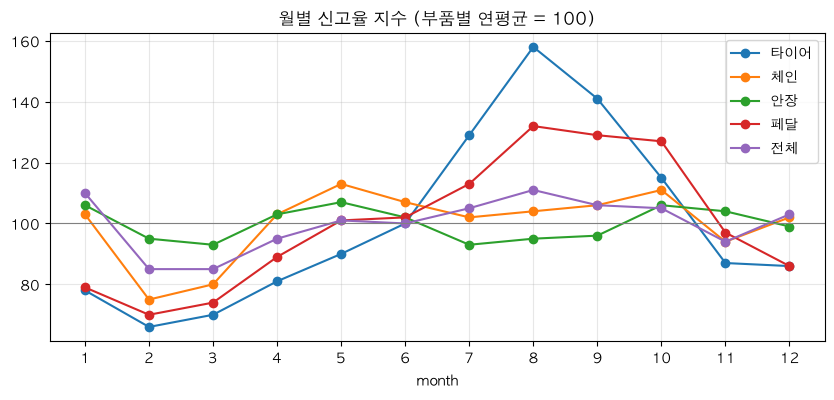

,타이어,체인,안장,페달,전체
최고 달,8.0,5.0,5.0,8.0,8.0
최고,158.0,113.0,107.0,132.0,111.0
최저 달,2.0,2.0,3.0,2.0,2.0
최저,66.0,75.0,93.0,70.0,85.0
진폭(최고-최저),92.0,38.0,14.0,62.0,26.0


In [6]:
by_month = rate_by(eda, "month")[list(PARTS.values())]
mi = (100 * by_month / by_month.mean()).round(0)
save_tab(mi, "month_index")
ax = mi.plot(figsize=(10, 4), marker="o", title="월별 신고율 지수 (부품별 연평균 = 100)")
ax.axhline(100, color="gray", lw=0.8); ax.set_xticks(range(1, 13)); ax.grid(alpha=0.3); save_fig("month_index")
pd.DataFrame({"최고 달": mi.idxmax(), "최고": mi.max(), "최저 달": mi.idxmin(), "최저": mi.min(), "진폭(최고-최저)": mi.max() - mi.min()}).T

## 4. 기온

평균기온을 4℃ 구간으로 나눠 신고율을 본다. 1차 분석에서는 추울 때와 더울 때 모두 높은 U자형이었다.

주의: 기온은 계절과 한 몸이다. 겨울에는 이용자 구성(정기권 통근 위주)과 정비 여건도 다르므로, 여기서 보이는 차이가 전부 "기온 때문"은 아니다. 6절에서 그 주의 수준 대비로 다시 본다.

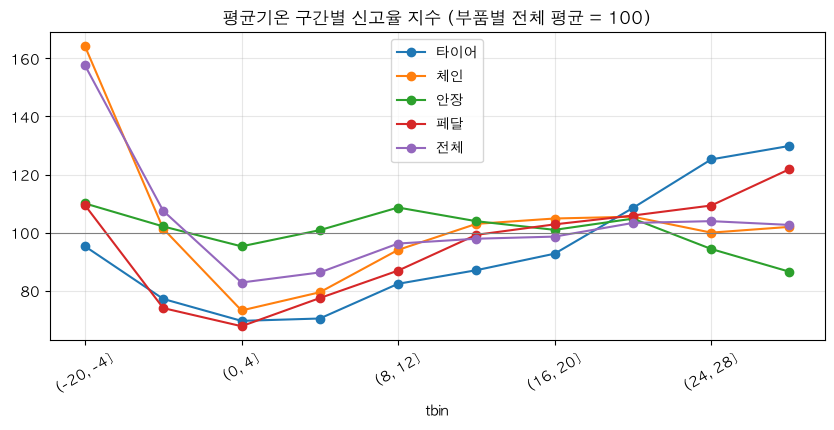

,일수,타이어,체인,안장,페달,전체
tbin,,,,,,
"(-20, -4]",60,7.5,14.0,8.1,4.7,57.6
"(-4, 0]",88,6.0,8.7,7.5,3.2,39.3
"(0, 4]",135,5.4,6.2,7.0,2.9,30.3
"(4, 8]",113,5.5,6.8,7.4,3.3,31.5
"(8, 12]",114,6.4,8.0,8.0,3.7,35.2
"(12, 16]",161,6.8,8.8,7.7,4.3,35.8
"(16, 20]",167,7.3,9.0,7.4,4.4,36.0
"(20, 24]",204,8.5,9.0,7.7,4.5,37.8
"(24, 28]",207,9.8,8.5,7.0,4.7,38.0


In [7]:
bins = [-20, -4, 0, 4, 8, 12, 16, 20, 24, 28, 36]
t = rate_by(eda.assign(tbin=pd.cut(eda.tavg, bins)), "tbin")
save_tab(t.round(1), "temp")
ax = t[list(PARTS.values())].div(overall).mul(100).plot(figsize=(10, 4), marker="o", title="평균기온 구간별 신고율 지수 (부품별 전체 평균 = 100)")
ax.axhline(100, color="gray", lw=0.8); ax.grid(alpha=0.3); plt.xticks(rotation=30); save_fig("temp")
t.round(1)

## 5. 비

**당일 비**는 이용을 줄인다(노출 쪽). 궁금한 것은 **전날 비**다: 비를 맞은 자전거가 다음 날 더 많이 신고되는가?
당일 비의 영향을 섞지 않으려고 **당일에 비가 오지 않은 날만** 골라, 전날 강수량에 따라 나눈다.

In [8]:
dry = eda[eda.rain_mm == 0]                                         # 당일 무강수인 날만
lag = pd.cut(dry.rain_lag1, [-np.inf, 0, 5, 20, np.inf], labels=["전날 비 없음", "0~5mm", "5~20mm", "20mm 초과"])
t = rate_by(dry.assign(lag=lag), "lag")
t["전체 지수(비 없음=100)"] = (100 * t["전체"] / t.loc["전날 비 없음", "전체"]).round(0)
save_tab(t.round(1), "rain_lag1")

,일수,타이어,체인,안장,페달,전체,전체 지수(비 없음=100)
lag,,,,,,,
전날 비 없음,729,7.5,8.6,7.5,4.3,36.5,100.0
0~5mm,155,8.3,8.8,7.5,4.6,38.3,105.0
5~20mm,42,8.3,9.1,7.5,4.7,37.3,102.0
20mm 초과,23,9.4,8.1,7.2,4.8,37.2,102.0


In [9]:
# 당일 비: 비 오는 날의 신고율(분자·분모가 모두 줄어든 뒤의 비율)과 대여 건수
today = pd.cut(eda.rain_mm, [-np.inf, 0, 1, 10, 30, np.inf], labels=["없음", "1mm 미만", "1~10mm", "10~30mm", "30mm 초과"])
t = rate_by(eda.assign(today=today), "today")
t["하루 평균 대여"] = eda.groupby(today, observed=True).rentals.mean().round(0)
t["전체 지수(없음=100)"] = (100 * t["전체"] / t.loc["없음", "전체"]).round(0)
save_tab(t.round(1), "rain_today")

,일수,타이어,체인,안장,페달,전체,하루 평균 대여,전체 지수(없음=100)
today,,,,,,,,
없음,949,7.7,8.7,7.5,4.3,36.8,125961.0,100.0
1mm 미만,107,8.2,8.4,6.9,4.3,36.4,105754.0,99.0
1~10mm,174,8.1,8.2,7.2,4.1,35.8,98900.0,97.0
10~30mm,71,8.7,8.1,6.7,4.0,35.6,75975.0,96.0
30mm 초과,62,8.4,6.8,5.8,3.5,32.0,54832.0,87.0


## 6. 계절·추세를 걷어 내고 다시 보기 — "그 무렵 수준 대비"

지금까지의 표는 날씨 효과에 계절과 장기 추세가 섞여 있다(예: 추운 날은 전부 겨울이고, 겨울은 다른 이유로도 다르다).
그래서 각 날의 신고율을 **그 날 앞뒤 2주(29일)의 중앙값으로 나눈 값**을 만든다. 이 값이 1.10이면 "그 무렵 평소보다 10% 높은 날"이다.
계절과 수준 변화(레짐)는 앞뒤 2주 안에서 거의 같으므로 나눗셈으로 사라지고, 요일·날씨처럼 날마다 달라지는 것만 남는다.

같은 계산을 기간을 둘로 나눠서도 한다(2021-04 ~ 2022-12, 2023 ~ 2024). 두 기간의 값이 비슷하면 "수준이 달라도 상대 효과는 유지된다"는 뜻이고, 이것이 테스트 구간(다른 레짐)에서도 모형이 쓸모 있을 근거가 된다.

In [10]:
full = m[~m.no_service].set_index("date")
def rel(col):
    """그날 신고율 ÷ 앞뒤 2주(29일) 신고율 중앙값. 구간 가장자리에서도 계산되도록 전체 기간 자료로 만든 뒤 EDA 구간만 꺼낸다"""
    r = full[col] / full.rentals
    return (r / r.rolling(29, center=True, min_periods=15).median()).reindex(eda.date).to_numpy()
for c in PARTS:
    eda["rel_" + c] = rel(c)
eda["period"] = np.where(eda.date < "2023-01-01", "2021-04~2022", "2023~2024")
REL = ["rel_" + c for c in PARTS]

def rel_by(df, key):
    """그룹별 '그 무렵 수준 대비' 중앙값(1.00 = 평소와 같음)"""
    return df.groupby(key, observed=True)[REL].median().rename(columns=lambda c: PARTS[c[4:]])

def rel_two(key_series, name):
    """전체 신고율의 상대값을 기간별로 나란히 보여 준다(일수 포함)"""
    d = eda.assign(k=key_series)
    out = d.groupby(["k", "period"], observed=True).rel_total_faults.median().unstack().round(2)
    out.insert(0, "전체 기간", d.groupby("k", observed=True).rel_total_faults.median().round(2))
    out["일수"] = d.groupby("k", observed=True).size()
    return save_tab(out, name)

print("요일")
display(rel_two(eda.dow.map(DOW).astype(pd.CategoricalDtype(list(DOW.values()), ordered=True)), "rel_dow"))

요일


period,전체 기간,2021-04~2022,2023~2024,일수
k,,,,
월,1.10,1.10,1.10,195
화,1.06,1.05,1.07,194
수,1.05,1.05,1.05,194
목,1.02,1.01,1.02,195
금,1.00,1.00,0.99,195
토,0.87,0.87,0.88,195
일,0.90,0.87,0.91,195


In [11]:
print("쉬는 날 구분")
display(rel_two(pd.Series(kind, index=eda.index), "rel_dayoff"))
print("전날 비 (당일 무강수인 날만)")
lag_all = pd.cut(eda.rain_lag1, [-np.inf, 0, 5, 20, np.inf], labels=["전날 비 없음", "0~5mm", "5~20mm", "20mm 초과"]).where(eda.rain_mm == 0)
display(rel_two(lag_all, "rel_rain_lag1"))
print("당일 비")
display(rel_two(today, "rel_rain_today"))

쉬는 날 구분


period,전체 기간,2021-04~2022,2023~2024,일수
k,,,,
그 밖의 평일,1.03,1.03,1.03,711
쉬는 날 다음 첫 근무일,1.11,1.11,1.11,212
주말,0.88,0.87,0.90,390
평일 공휴일,0.87,0.86,0.89,50


전날 비 (당일 무강수인 날만)


period,전체 기간,2021-04~2022,2023~2024,일수
k,,,,
전날 비 없음,1.01,1.00,1.02,729
0~5mm,1.04,1.06,1.03,155
5~20mm,1.03,1.07,1.02,42
20mm 초과,1.01,1.01,1.01,23


당일 비


period,전체 기간,2021-04~2022,2023~2024,일수
k,,,,
없음,1.02,1.01,1.02,949
1mm 미만,0.98,0.95,0.98,107
1~10mm,0.97,0.99,0.95,174
10~30mm,0.90,0.92,0.86,71
30mm 초과,0.84,0.87,0.83,62


In [12]:
print("평균기온 (그 무렵 평소보다 얼마나 추운·더운 날인가가 아니라, 그날의 기온 구간)")
display(rel_two(pd.cut(eda.tavg, [-20, -4, 0, 4, 12, 20, 24, 28, 36]), "rel_temp"))
# 계절 안에서의 기온 효과를 더 직접 보려면: 그날 기온이 앞뒤 2주 평균보다 몇 ℃ 높거나 낮았는가
tav = full.tavg
eda["t_anom"] = (tav - tav.rolling(29, center=True, min_periods=15).mean()).reindex(eda.date).to_numpy()
print("기온 편차(그날 평균기온 − 앞뒤 2주 평균), 겨울(12~2월)과 그 밖을 나눠서")
t = eda.assign(k=pd.cut(eda.t_anom, [-20, -6, -3, -1, 1, 3, 6, 20]), winter=np.where(eda.month.isin([12, 1, 2]), "겨울(12~2월)", "그 밖"))
out = t.groupby(["k", "winter"], observed=True).rel_total_faults.median().unstack().round(2)
out["일수"] = t.groupby("k", observed=True).size()
save_tab(out, "rel_temp_anom")

평균기온 (그 무렵 평소보다 얼마나 추운·더운 날인가가 아니라, 그날의 기온 구간)


period,전체 기간,2021-04~2022,2023~2024,일수
k,,,,
"(-20, -4]",1.33,1.33,1.49,60
"(-4, 0]",1.02,1.00,1.03,88
"(0, 4]",0.93,0.90,0.95,135
"(4, 12]",1.00,1.00,0.99,227
"(12, 20]",1.00,1.00,1.00,328
"(20, 24]",1.00,1.00,0.99,204
"(24, 28]",1.00,1.01,1.00,207
"(28, 36]",1.01,1.00,1.03,114


기온 편차(그날 평균기온 − 앞뒤 2주 평균), 겨울(12~2월)과 그 밖을 나눠서


winter,겨울(12~2월),그 밖,일수
k,,,
"(-20, -6]",1.52,1.02,37
"(-6, -3]",1.26,0.97,146
"(-3, -1]",1.02,1.00,260
"(-1, 1]",1.00,1.01,429
"(1, 3]",0.93,1.00,321
"(3, 6]",0.90,0.99,138
"(6, 20]",0.86,0.97,32


In [13]:
# 부품별로: 요일·전날 비·한파가 어느 부품에서 큰가(그 무렵 수준 대비)
rows = {
    "월요일": eda.dow == 1, "토·일": eda.dow >= 6,
    "전날 비 5mm 이상(당일 무강수)": (eda.rain_mm == 0) & (eda.rain_lag1 >= 5),
    "당일 비 10mm 이상": eda.rain_mm >= 10,
    "평균기온 -4℃ 이하": eda.tavg <= -4, "평균기온 28℃ 이상": eda.tavg >= 28,
    "얼었다 녹은 날(freeze_thaw)": eda.freeze_thaw, "눈 온 날(신적설 1cm 이상)": eda.snow_cm >= 1,
}
t = pd.DataFrame({k: eda[v][REL].median() for k, v in rows.items()}).T.rename(columns=lambda c: PARTS[c[4:]]).round(2)
t["일수"] = [int(v.sum()) for v in rows.values()]
save_tab(t, "rel_parts")

,타이어,체인,안장,페달,전체,일수
월요일,1.11,1.07,1.12,1.11,1.10,195
토·일,0.92,0.91,0.80,0.86,0.88,390
전날 비 5mm 이상(당일 무강수),1.02,1.03,1.01,1.05,1.02,65
당일 비 10mm 이상,0.94,0.85,0.83,0.80,0.87,133
평균기온 -4℃ 이하,1.22,1.50,0.98,1.38,1.33,60
평균기온 28℃ 이상,1.02,1.01,1.01,1.05,1.01,118
얼었다 녹은 날(freeze_thaw),0.99,0.96,1.01,0.97,0.99,234
눈 온 날(신적설 1cm 이상),1.00,0.90,0.86,0.84,0.92,25


## 7. 신고가 덜 잡힌 기간(2023-09-07 ~ 10-10)을 넣을 때와 뺄 때

이 5주는 앱 접속 장애 직후로, 신고율이 평소의 약 60%였다(`report_anomaly`). 넣고 본 결과가 뺀 결과와 얼마나 다른지 확인해, EDA·학습에서 뺄지 정하는 근거로 삼는다.

- 월별 지수: 9월·10월이 눌리는지
- "그 무렵 수준 대비" 값: 이 방식은 앞뒤 2주로 나누므로 영향이 작을 것으로 기대한다

In [14]:
ex = eda[~eda.report_anomaly]
bm_in, bm_ex = rate_by(eda, "month")["전체"], rate_by(ex, "month")["전체"]
cmp = pd.DataFrame({"포함": (100 * bm_in / bm_in.mean()).round(0), "제외": (100 * bm_ex / bm_ex.mean()).round(0)})
cmp["차이"] = cmp["포함"] - cmp["제외"]
print("월별 지수(전체 신고율)")
display(save_tab(cmp, "anomaly_month").T)
print("연도별 신고율(대여 만 건당)")
display(pd.DataFrame({"포함": rate_by(eda, "year")["전체"], "제외": rate_by(ex, "year")["전체"]}).round(1).T)
print("요일별 '그 무렵 수준 대비'")
display(pd.DataFrame({"포함": eda.groupby("dow").rel_total_faults.median(), "제외": ex.groupby("dow").rel_total_faults.median()}).rename(index=DOW).round(2).T)
print("이 기간의 요일별 신고율(대여 만 건당) — 기간 안에서도 요일 패턴은 남아 있는가")
an = eda[eda.report_anomaly]
display((rate_by(an, "dow").rename(index=DOW)[["일수", "전체"]].round(1)).T)

월별 지수(전체 신고율)


month,1,2,3,4,5,6,7,8,9,10,11,12
포함,110.0,85.0,85.0,95.0,101.0,100.0,105.0,111.0,106.0,105.0,94.0,103.0
제외,109.0,84.0,84.0,94.0,100.0,99.0,104.0,109.0,116.0,107.0,93.0,102.0
차이,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,-10.0,-2.0,1.0,1.0


연도별 신고율(대여 만 건당)


year,2021,2022,2023,2024
포함,45.1,38.6,33.7,32.2
제외,45.1,38.6,34.9,32.2


요일별 '그 무렵 수준 대비'


dow,월,화,수,목,금,토,일
포함,1.1,1.06,1.05,1.02,1.0,0.87,0.9
제외,1.1,1.06,1.05,1.02,1.0,0.87,0.9


이 기간의 요일별 신고율(대여 만 건당) — 기간 안에서도 요일 패턴은 남아 있는가


dow,월,화,수,목,금,토,일
일수,5.0,5.0,4.0,5.0,5.0,5.0,5.0
전체,26.1,27.6,24.6,26.0,23.3,21.7,22.3


## 8. 반기별 추이 (참고)

분석 구간 안에서도 수준이 서서히 내려간다. 모형에는 이 흐름을 따라갈 장치(최근 4주 신고율)가 필요하다.

In [15]:
h = eda.year.astype(str) + np.where(eda.month <= 6, " 상반기", " 하반기")
save_tab(rate_by(eda.assign(h=h), "h").round(1), "half_year")

,일수,타이어,체인,안장,페달,전체
h,,,,,,
2021 상반기,84,7.8,12.6,10.2,4.8,44.8
2021 하반기,184,10.9,10.4,9.6,4.8,45.2
2022 상반기,181,6.4,7.5,7.7,3.4,35.7
2022 하반기,183,9.6,8.6,8.3,4.7,40.9
2023 상반기,181,6.5,7.4,7.4,3.4,33.9
2023 하반기,184,8.1,7.3,6.8,4.5,33.6
2024 상반기,182,5.3,8.6,6.3,3.8,31.5
2024 하반기,184,8.1,8.6,4.9,5.2,32.9


## 9. 더위 — 이용량이 줄어서 그런 것은 아닌가

"더위 효과가 안 보이는 것은 더운 날 이용량 자체가 줄어서가 아닐까?"를 확인한다.
비가 오지 않은 날만 골라, 최고기온 구간별로 **대여량**과 **신고율**이 그 무렵 평소(앞뒤 2주 중앙값)의 몇 배인지 본다.
(신고율은 이미 대여량으로 나눈 값이라, 이용량이 줄어도 그 자체로는 신고율이 달라지지 않는다.)

In [16]:
rent_rel = (full.rentals / full.rentals.rolling(29, center=True, min_periods=15).median()).reindex(eda.date).to_numpy()
d = eda.assign(rent_rel=rent_rel)
d = d[d.rain_mm == 0]
t = d.groupby(pd.cut(d.tmax, [-20, 0, 5, 25, 30, 33, 40]), observed=True).agg(
        대여량_평소대비=("rent_rel", "median"), 신고율_평소대비=("rel_total_faults", "median"), 일수=("date", "size")).round(2)
save_tab(t, "heat_usage")

,대여량_평소대비,신고율_평소대비,일수
tmax,,,
"(-20, 0]",0.77,1.38,44
"(0, 5]",1.00,1.03,85
"(5, 25]",1.05,1.01,470
"(25, 30]",1.06,1.01,185
"(30, 33]",1.05,1.01,103
"(33, 40]",1.03,1.03,62


## 10. 주 단위로 보면 — 신고 건수는 이용량이 얼마나 정하나

요일 효과는 일주일을 더하면 서로 상쇄된다. 그러면 **주간 신고 건수**의 오르내림은 무엇이 정하는가?

신고 건수 = 대여량 × 신고율 이므로, 주간 건수의 변동을 "대여량의 몫"과 "신고율의 몫"으로 나눠 본다.
- 로그를 쓰는 이유: 곱셈 관계가 덧셈이 되어(log 건수 = log 대여량 + log 신고율) 변동을 몫으로 나누기 쉽다.
- R² = 주간 건수의 변동 가운데 대여량만으로 설명되는 비율.

In [17]:
wk = (m[m.date.between("2021-04-12", "2024-12-29")].set_index("date")[list(PARTS) + ["rentals", "tavg"]]
        .resample("W").agg({**{c: "sum" for c in PARTS}, "rentals": "sum", "tavg": "mean"}))     # 월~일 한 주씩 합계(기온은 평균)
rows = []
for c, name in PARTS.items():
    ly, lx = np.log(wk[c]), np.log(wk.rentals)
    rate = wk[c] / wk.rentals * 1e4
    rows.append({"부품": name,
                 "대여량만으로 설명되는 비율(R²)": np.corrcoef(ly, lx)[0, 1] ** 2,
                 "신고율 하위 5% 주": rate.quantile(.05), "신고율 상위 5% 주": rate.quantile(.95)})
save_tab(pd.DataFrame(rows).set_index("부품").round(2), "weekly_decomp")

,대여량만으로 설명되는 비율(R²),신고율 하위 5% 주,신고율 상위 5% 주
부품,,,
타이어,0.74,4.50,12.10
체인,0.74,5.75,12.72
안장,0.70,4.41,10.13
페달,0.85,2.70,5.92
전체,0.80,27.29,49.24


아주 단순한 예측 두 가지로 같은 것을 다시 확인한다(한 주 앞 예측, 평가 2022-07 ~ 2024-12, 평균 오차율 MAPE).

- **나이브**: 다음 주 건수 = 이번 주 건수
- **지난주 신고율 × 그 주의 실제 대여량**: 대여량을 미리 정확히 안다고 가정한 값이다. 실제로는 대여량도 예측해야 하므로 이보다 나빠진다. "대여량을 알면 얼마나 맞힐 수 있나"의 상한선으로 본다.

둘의 차이가 크면, 나이브를 이기는 힘의 대부분이 이용량에서 나온다는 뜻이다.

In [18]:
def mape(actual, pred):
    return float((np.abs(actual - pred) / actual).mean() * 100)

ev = slice("2022-07-01", "2024-12-31")
rows, errs = [], {}
for c, name in PARTS.items():
    y, x = wk[c], wk.rentals
    naive = y.shift(1)                                   # 지난주 건수
    by_rate = (y / x).shift(1) * x                       # 지난주 신고율 × 이번 주 실제 대여량
    rows.append({"부품": name, "나이브": mape(y[ev], naive[ev]), "지난주 신고율 × 실제 대여량": mape(y[ev], by_rate[ev])})
    errs[name] = (y / by_rate - 1)[ev]                   # 실제 ÷ 예측 − 1 (양수 = 실제가 더 많았다)
save_tab(pd.DataFrame(rows).set_index("부품").round(1), "weekly_naive_vs_rate")

,나이브,지난주 신고율 × 실제 대여량
부품,,
타이어,21.4,8.1
체인,25.0,11.9
안장,26.1,8.7
페달,27.7,12.6
전체,22.3,7.9


대여량을 알아도 못 맞히는 주는 어떤 주인가 — 신고율 쪽에서 설명해야 할 부분이다.

In [19]:
e = pd.DataFrame({"실제÷예측−1": errs["전체"], "주 평균기온": wk.tavg[ev], "신고 건수": wk.total_faults[ev]})
print("주 평균기온 0℃ 이하인 주:", int((e["주 평균기온"] <= 0).sum()), "주, 평균 오차", round(e[e["주 평균기온"] <= 0]["실제÷예측−1"].mean(), 2),
      "/ 그 밖의 주 평균 오차", round(e[e["주 평균기온"] > 0]["실제÷예측−1"].mean(), 2))
save_tab(e.reindex(e["실제÷예측−1"].abs().sort_values(ascending=False).index).head(8).round(2), "weekly_big_errors")

주 평균기온 0℃ 이하인 주: 12 주, 평균 오차 0.16 / 그 밖의 주 평균 오차 -0.0


,실제÷예측−1,주 평균기온,신고 건수
date,,,
2023-01-22,1.15,-2.71,2710
2023-12-24,1.04,-7.30,2470
2023-12-31,-0.56,1.13,1296
2022-12-04,0.55,0.64,2561
2023-10-15,0.36,16.84,4694
2022-12-18,0.29,-4.81,1511
2023-01-29,-0.29,-6.84,1158
2023-12-17,0.28,2.81,1378
